In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split
from torchvision import models
from torchsummary import summary
import os
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [2]:
# =======================
# STEP 0: Initialize
# =======================
EPOCHS = 10
BATCH_SIZE = 16
LEARNING_RATE = 0.001

In [3]:
# =======================
# STEP 1: Data Preparation
# =======================

# Transforms for training and validation
data_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Load the full dataset from the root directory
data_dir = "/content/flower_photos"
full_dataset = datasets.ImageFolder(root=data_dir, transform=data_transforms)

# Split into 80% training and 20% validation sets
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

# Create PyTorch DataLoaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

# Verify classes and batch shape
print("Classes:", full_dataset.classes)
images, labels = next(iter(train_loader))
print("Batch shape:", images.shape, "Labels shape:", labels.shape)

Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
Batch shape: torch.Size([16, 3, 224, 224]) Labels shape: torch.Size([16])


In [4]:
# ===========================
# STEP 2: Load Pretrained Model
# ===========================
from torchvision.models import ResNet50_Weights

model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, 5)  # for 5-class classification

# Freeze all but final layer
for param in model.parameters():
    param.requires_grad = False
for param in model.fc.parameters():
    param.requires_grad = True

# Move model to device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)


In [5]:
# ===================
# STEP 3: Loss & Optimizer
# ===================

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

In [6]:
all_preds = []
all_labels = []

def train_model(model, criterion, optimizer, train_loader, val_loader, epochs=10):

    for epoch in range(epochs):
        model.train()
        train_correct = 0
        train_total = 0
        running_loss = 0.0

        print(f"\nEpoch {epoch + 1}/{epochs}")
        print("-" * 30)

        for i, (images, labels) in enumerate(train_loader):
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            _, preds = torch.max(outputs, 1)
            batch_correct = (preds == labels).sum().item()
            train_correct += batch_correct
            train_total += labels.size(0)

        train_acc = train_correct / train_total
        print(f"Epoch {epoch+1} Summary - Loss: {running_loss:.4f}, Train Accuracy: {train_acc:.4f}")

        # Validation
        model.eval()
        val_correct = 0
        val_total = 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, preds = torch.max(outputs, 1)

                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())

                val_correct += (preds == labels).sum().item()
                val_total += labels.size(0)

        val_acc = val_correct / val_total
        print(f"Validation Accuracy: {val_acc:.4f}")


In [7]:
# ===================
# Train the model
# ===================
train_model(model, criterion, optimizer, train_loader, val_loader, epochs=EPOCHS)


Epoch 1/10
------------------------------
Epoch 1 Summary - Loss: 137.2056, Train Accuracy: 0.7844
Validation Accuracy: 0.8924

Epoch 2/10
------------------------------
Epoch 2 Summary - Loss: 70.2309, Train Accuracy: 0.8992
Validation Accuracy: 0.9169

Epoch 3/10
------------------------------
Epoch 3 Summary - Loss: 56.1079, Train Accuracy: 0.9097
Validation Accuracy: 0.9183

Epoch 4/10
------------------------------
Epoch 4 Summary - Loss: 48.0948, Train Accuracy: 0.9278
Validation Accuracy: 0.9169

Epoch 5/10
------------------------------
Epoch 5 Summary - Loss: 39.9493, Train Accuracy: 0.9390
Validation Accuracy: 0.9210

Epoch 6/10
------------------------------
Epoch 6 Summary - Loss: 36.3068, Train Accuracy: 0.9479
Validation Accuracy: 0.9237

Epoch 7/10
------------------------------
Epoch 7 Summary - Loss: 31.9888, Train Accuracy: 0.9544
Validation Accuracy: 0.9196

Epoch 8/10
------------------------------
Epoch 8 Summary - Loss: 29.6453, Train Accuracy: 0.9561
Validation 

**Confusion Matrix**

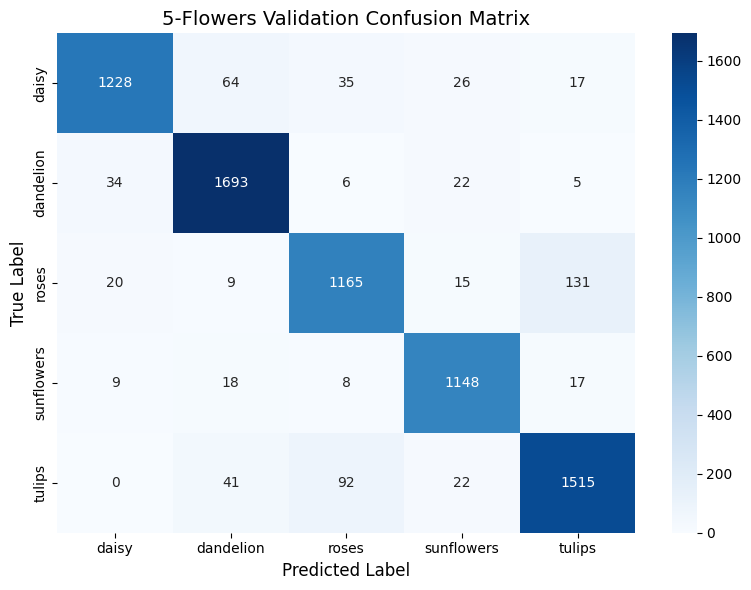

In [8]:
# Get class names (works whether val_dataset is a Subset or ImageFolder)
class_names = (
    val_dataset.dataset.classes
    if hasattr(val_dataset, "dataset")
    else full_dataset.classes
)

# Compute and plot the Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)
plt.title("5-Flowers Validation Confusion Matrix", fontsize=14)
plt.tight_layout()
plt.show()